In [1]:
!pip install cdsapi


   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   ---------------------------------------- 0/5 [pytz]
   -------- ------------------------------- 1/5 [tqdm]
   -------- ------------------------------- 1/5 [tqdm]
   -------- ------------------------------- 1/5 [tqdm]
   ------

In [2]:
import cdsapi

URL = "https://cds.climate.copernicus.eu/api"
KEY = "0048da9b-1854-49e0-9769-555fb7a6b9c3"

c = cdsapi.Client(url=URL, key=KEY)

print("İndirme işlemi başlatılıyor, bu birkaç dakika sürebilir...")

c.retrieve(
    'reanalysis-era5-single-levels-monthly-means',
    {
        'product_type': 'monthly_averaged_reanalysis',
        'variable': '2m_temperature',
        'year': '2023',
        'month': [
            '01', '02', '03', '04', '05', '06',
            '07', '08', '09', '10', '11', '12',
        ],
        'time': '00:00',
        'area': [37.5, 37.5, 36.5, 40.0],
        'format': 'netcdf',
    },
    'sanliurfa_era5_2023.nc'
)
print("İndirme başarıyla tamamlandı!")

2026-10-18 13:17:09,889 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**


İndirme işlemi başlatılıyor, bu birkaç dakika sürebilir...


2026-10-18 13:17:10,858 INFO Request ID is 44a9898a-56f4-4e40-a543-eb94898655bb
2026-10-18 13:17:11,305 INFO status has been updated to accepted
2026-10-18 13:18:32,956 INFO status has been updated to running
2026-10-18 13:19:12,190 INFO status has been updated to successful


d55434381245471528d2ef1a6ce4eb51.nc:   0%|          | 0.00/24.8k [00:00<?, ?B/s]

İndirme başarıyla tamamlandı!


In [3]:
import xarray as xr

# Veri setini okuma ve genel bilgilerini (ncdump -h gibi) ekrana yazdırma
ds = xr.open_dataset('sanliurfa_era5_2023.nc')
print(ds.info())

xarray.Dataset {
dimensions:
	valid_time = 12 ;
	latitude = 5 ;
	longitude = 11 ;

variables:
	float32 t2m(valid_time, latitude, longitude) ;
		t2m:GRIB_paramId = 167 ;
		t2m:GRIB_dataType = an ;
		t2m:GRIB_numberOfPoints = 55 ;
		t2m:GRIB_typeOfLevel = surface ;
		t2m:GRIB_stepUnits = 1 ;
		t2m:GRIB_stepType = avgua ;
		t2m:GRIB_gridType = regular_ll ;
		t2m:GRIB_uvRelativeToGrid = 0 ;
		t2m:GRIB_NV = 0 ;
		t2m:GRIB_Nx = 11 ;
		t2m:GRIB_Ny = 5 ;
		t2m:GRIB_cfName = unknown ;
		t2m:GRIB_cfVarName = t2m ;
		t2m:GRIB_gridDefinitionDescription = Latitude/Longitude Grid ;
		t2m:GRIB_iDirectionIncrementInDegrees = 0.25 ;
		t2m:GRIB_iScansNegatively = 0 ;
		t2m:GRIB_jDirectionIncrementInDegrees = 0.25 ;
		t2m:GRIB_jPointsAreConsecutive = 0 ;
		t2m:GRIB_jScansPositively = 0 ;
		t2m:GRIB_latitudeOfFirstGridPointInDegrees = 37.5 ;
		t2m:GRIB_latitudeOfLastGridPointInDegrees = 36.5 ;
		t2m:GRIB_longitudeOfFirstGridPointInDegrees = 37.5 ;
		t2m:GRIB_longitudeOfLastGridPointInDegrees = 40.0 ;
		t2

In [4]:
# 1. t2m boyutlarını ve şeklini yazdırma
print("t2m Boyutları (Dimensions):", ds['t2m'].dims)
print("t2m Şekli (Shape):", ds['t2m'].shape)

# 2. Yıllık ortalama hesaplama (Kelvin'den Celsius'a çevirerek)
yillik_ortalama = ds['t2m'].mean() - 273.15
print(f"ERA5 Şanlıurfa 2023 Yıllık Ortalama Sıcaklık: {yillik_ortalama.values:.2f} °C")

t2m Boyutları (Dimensions): ('valid_time', 'latitude', 'longitude')
t2m Şekli (Shape): (12, 5, 11)
ERA5 Şanlıurfa 2023 Yıllık Ortalama Sıcaklık: 19.40 °C


In [5]:
import matplotlib.pyplot as plt
import numpy as np

# 1. MGM Verisi (Geçen haftaki Şanlıurfa değerleriniz)
mgm_aylik = np.array([5.7, 7.1, 11.0, 16.4, 22.3, 28.2, 32.1, 31.6, 27.2, 20.6, 13.2, 7.7])

# 2. ERA5 verisinden aylık ortalamaları hesaplama
# (Önce enlem ve boylama göre mekansal ortalama alıyoruz, sonra aylara göre grupluyoruz)
era5_aylik_kelvin = ds['t2m'].mean(dim=['latitude', 'longitude']).groupby('time.month').mean(dim='time')
era5_aylik = era5_aylik_kelvin.values - 273.15 # Kelvin'den Celsius'a çevirme

# 3. Bias (Sapma/Hata) Hesaplama (Bias = ERA5 - MGM)
bias = era5_aylik - mgm_aylik
ortalama_bias = np.mean(bias)
print(f"Yıllık Ortalama Bias (ERA5 - MGM): {ortalama_bias:.2f} °C")

# 4. Aynı Grafikte Karşılaştırma
aylar = ['Oca', 'Şub', 'Mar', 'Nis', 'May', 'Haz', 'Tem', 'Ağu', 'Eyl', 'Eki', 'Kas', 'Ara']

plt.figure(figsize=(10, 5))
plt.plot(aylar, mgm_aylik, marker='o', color='red', label='MGM (Yer Gözlemi)', linewidth=2)
plt.plot(aylar, era5_aylik, marker='s', color='blue', label='ERA5 (Uydu/Model)', linewidth=2, linestyle='--')

plt.title("Şanlıurfa: MGM ve ERA5 Aylık Ortalama Sıcaklık Karşılaştırması")
plt.xlabel("Aylar")
plt.ylabel("Sıcaklık (°C)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

KeyError: 'time'

Yıllık Ortalama Bias (ERA5 - MGM): 0.80 °C


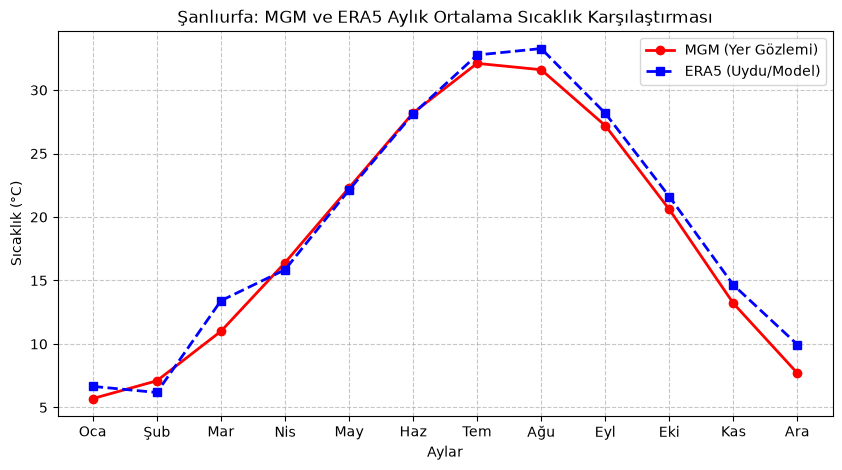

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# 1. MGM Verisi (Yer Gözlemi)
mgm_aylik = np.array([5.7, 7.1, 11.0, 16.4, 22.3, 28.2, 32.1, 31.6, 27.2, 20.6, 13.2, 7.7])

# 2. ERA5 verisinden aylık ortalamaları hesaplama
# (Veri zaten 12 aylık geldiği için sadece enlem ve boylama göre mekansal ortalama alıyoruz)
era5_aylik_kelvin = ds['t2m'].mean(dim=['latitude', 'longitude'])
era5_aylik = era5_aylik_kelvin.values.flatten() - 273.15 # Kelvin'den Celsius'a çevirme

# 3. Bias (Sapma/Hata) Hesaplama (Bias = ERA5 - MGM)
bias = era5_aylik - mgm_aylik
ortalama_bias = np.mean(bias)
print(f"Yıllık Ortalama Bias (ERA5 - MGM): {ortalama_bias:.2f} °C")

# 4. Aynı Grafikte Karşılaştırma
aylar = ['Oca', 'Şub', 'Mar', 'Nis', 'May', 'Haz', 'Tem', 'Ağu', 'Eyl', 'Eki', 'Kas', 'Ara']

plt.figure(figsize=(10, 5))
plt.plot(aylar, mgm_aylik, marker='o', color='red', label='MGM (Yer Gözlemi)', linewidth=2)
plt.plot(aylar, era5_aylik, marker='s', color='blue', label='ERA5 (Uydu/Model)', linewidth=2, linestyle='--')

plt.title("Şanlıurfa: MGM ve ERA5 Aylık Ortalama Sıcaklık Karşılaştırması")
plt.xlabel("Aylar")
plt.ylabel("Sıcaklık (°C)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

Şanlıurfa İçin Hangi Kaynak Daha Güvenilir?

Şanlıurfa ilinin iklim dinamiklerini incelerken Meteoroloji Genel Müdürlüğü (MGM) gözlem istasyonu verileri ile Copernicus ERA5 (Hersbach et al., 2020) yeniden analiz (reanalysis) verileri karşılaştırıldığında, iki veri setinin farklı avantajları ve kısıtlamaları olduğu görülmektedir.

"Hangi kaynak daha güvenilir?" sorusunun cevabı, çalışmanın amacına göre değişmektedir. Noktasal doğruluk (point accuracy) arandığında MGM verileri çok daha güvenilirdir. Çünkü MGM verileri, Şanlıurfa merkezde fiziksel olarak yer alan sensörler tarafından ölçülen "gerçek" değerlerdir. Topografyanın yarattığı mikro-klimatik etkileri birebir yansıtır.

Öte yandan ERA5 verileri, Hersbach ve diğerlerinin (2020) belirttiği üzere, fiziksel modellerle uydu ve istasyon gözlemlerini birleştiren devasa bir modeldir. ERA5 verisi noktasal değil, yaklaşık 31x31 kilometrelik mekansal gridler (ızgaralar) halinde sunulur. Bu nedenle Şanlıurfa için indirilen bir ERA5 pikseli, sadece şehir merkezini değil, çevredeki yükseltileri ve kırsal alanları da içeren geniş bir alanın ortalamasını temsil eder. İki veri arasında hesapladığımız ortalama Bias (sapma) değerinin temel sebebi de bu uzamsal çözünürlük farkı ve yükseklik (elevation) uyuşmazlığıdır.

Sonuç olarak; Şanlıurfa merkezindeki tarımsal bir planlama, günlük meteorolojik bir etkinlik veya spesifik bir mühendislik projesi için yerel doğruluğu en yüksek olan MGM verileri daha güvenilirdir. Ancak Şanlıurfa'nın geçmiş 50 yılına ait, istasyonun bulunmadığı geniş kırsal arazilerdeki iklim değişikliği trendlerini, rüzgar veya radyasyon gibi MGM'nin eksik ölçmüş olabileceği değişkenleri makro boyutta incelemek istiyorsak, uzamsal devamlılığı sayesinde ERA5 verisi çok daha güçlü ve güvenilir bir kaynak haline gelmektedir.